**CAPSTONE MODUL 3 : BIKE SHARING - IVAN SETYA ANANDA**

****
# **Business Understanding**
****

**Context:**
***
Bike-sharing systems represent a modern evolution of traditional bike rentals, automating the entire process from membership to rental and return. Users can effortlessly rent a bike from one station and return it to another
Focusing on the casual user segment—tourists, occasional riders, and non-regular commuters—offers substantial growth opportunities. Casual users typically seek flexibility and convenience, making them a lucrative market. The rich data generated by bike-sharing systems, including travel duration and station usage, provides valuable insights into urban mobility patterns. This data can be leveraged to enhance user experience, optimize operations, and drive targeted marketing strategies.


**Stakelhoders:**
***
Marketing Team ( Capital Bikeshare company)
 -  **Role:** Develop and suggest marketing campaigns to attract casual users.
 -  **Involvement:** Advertising, promotions, partnerships.


**Problem Statement:**
***
Despite a steady influx of casual users, our bike rental business has not fully capitalized on this market segment. We aim to identify the key factors influencing casual users' decision-making processes and develop targeted marketing and operational strategies to enhance their rental experience.


**Business Objective:**
***
Marketing Team Capital Bikeshare Company wants to know:
1.	Which Key Features are significant in predicting the casual shared bike demand
2.	How well those features describe the shared bike demand


***

In [1]:
# import the dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost.sklearn import XGBRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline


import warnings
warnings.filterwarnings('ignore')

In [2]:
bike = pd.read_csv('data_bike_sharing.csv')
bike

,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt
0,2011-12-09,0.62,1,0,4,0.3485,0.36,16,24,226,250
1,2012-06-17,0.64,1,0,2,0.5152,0.54,4,2,16,18
2,2011-06-15,0.53,1,0,2,0.6212,0.62,23,17,90,107
3,2012-03-31,0.87,2,0,2,0.3485,0.36,8,19,126,145
4,2012-07-31,0.55,1,0,3,0.6970,0.76,18,99,758,857
...,...,...,...,...,...,...,...,...,...,...,...
12160,2012-01-25,0.75,1,0,1,0.2273,0.24,7,14,243,257
12161,2012-07-06,0.62,1,0,3,0.7424,0.78,0,39,63,102
12162,2012-02-20,0.60,2,1,1,0.2121,0.24,5,0,6,6
12163,2012-03-31,0.77,2,0,2,0.4242,0.42,2,14,55,69


***
# **Data Collection and Preprocessing**
***

## **Collect Data**

In [3]:
bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      12165 non-null  object 
 1   hum         12165 non-null  float64
 2   weathersit  12165 non-null  int64  
 3   holiday     12165 non-null  int64  
 4   season      12165 non-null  int64  
 5   atemp       12165 non-null  float64
 6   temp        12165 non-null  float64
 7   hr          12165 non-null  int64  
 8   casual      12165 non-null  int64  
 9   registered  12165 non-null  int64  
 10  cnt         12165 non-null  int64  
dtypes: float64(3), int64(7), object(1)
memory usage: 1.0+ MB


There is data type error for `dteday` column; it should be `DateTime`, because of data time stamp type

There are data types error for `weathersit, holiday, season, hr` columns; it should be `Category`, because

## **Clean Data**

In [4]:
# percentage of missing values
missing_columns = (bike.isnull().sum())*100/len(bike)
missing_rows = (bike.isnull().sum(axis=1))*100/len(bike)
display(missing_columns,missing_rows)

dteday        0.0
hum           0.0
weathersit    0.0
holiday       0.0
season        0.0
atemp         0.0
temp          0.0
hr            0.0
casual        0.0
registered    0.0
cnt           0.0
dtype: float64

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
12160    0.0
12161    0.0
12162    0.0
12163    0.0
12164    0.0
Length: 12165, dtype: float64

<Axes: >

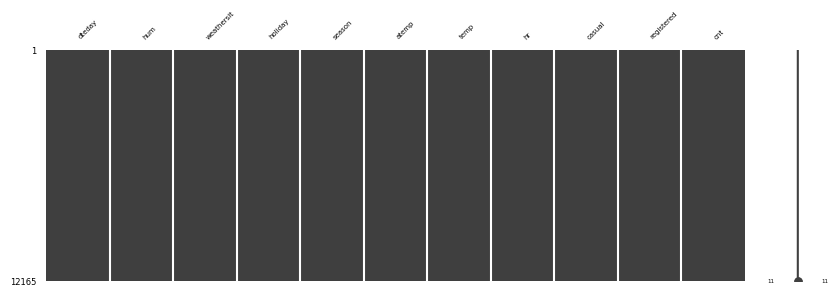

In [5]:
import missingno as msn
msn.matrix(bike,figsize=(10,3),fontsize=5)

In [6]:
# check duplicate
bike.duplicated().sum()

0

 ## **Feature Engineering**

In [7]:
bike['dteday'] = pd.to_datetime(bike['dteday'])
bike['day'] = bike['dteday'].dt.day_of_week
bike['month'] = bike['dteday'].dt.month

In [8]:
bike_new=bike[['hum','weathersit','holiday','season','temp','atemp','hr','cnt','day','month']]
bike_new.columns

Index(['hum', 'weathersit', 'holiday', 'season', 'temp', 'atemp', 'hr', 'cnt',
       'day', 'month'],
      dtype='object')

In [9]:
# Define a function to map months to quarters
def map_quarter(month):
    if month in [1, 2, 3]:
        return 1
    elif month in [4, 5, 6]:
        return 2
    elif month in [7, 8, 9]:
        return 3
    elif month in [10, 11, 12]:
        return 4
    else:
        return None  # Handle any unexpected values gracefully

# Apply the mapping function to create a new column 'quarter'
bike_new['quarter'] = bike_new['month'].apply(map_quarter)


In [10]:
bike_new['rush_hour'] = np.where(((bike_new['hr'] >= 7) & (bike_new['hr'] < 9)) | ((bike_new['hr'] >= 17) & (bike_new['hr'] < 19)), 1, 0)

In [11]:
bike_new['season'].replace({1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}, inplace=True)
bike_new['weathersit'].replace({1: 'Clear', 2: 'Mist', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'}, inplace=True)
bike_new['holiday'].replace({1:'Yes', 0:'No'}, inplace=True)

In [12]:
bike_new['season']=bike_new['season'].astype('category')
bike_new['weathersit']=bike_new['weathersit'].astype('category')
bike_new['month']=bike_new['month'].astype('category')
bike_new['day']=bike_new['day'].astype('category')
bike_new['holiday']=bike_new['holiday'].astype('category')
bike_new['quarter']=bike_new['quarter'].astype('category')
bike_new['rush_hour'] = bike_new['rush_hour'].astype('category')

In [13]:
bike_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   hum         12165 non-null  float64 
 1   weathersit  12165 non-null  category
 2   holiday     12165 non-null  category
 3   season      12165 non-null  category
 4   temp        12165 non-null  float64 
 5   atemp       12165 non-null  float64 
 6   hr          12165 non-null  int64   
 7   cnt         12165 non-null  int64   
 8   day         12165 non-null  category
 9   month       12165 non-null  category
 10  quarter     12165 non-null  category
 11  rush_hour   12165 non-null  category
dtypes: category(7), float64(3), int64(2)
memory usage: 559.8 KB


 ## **Outlier Handling**

In [14]:
num_columns = bike_new[['hum','temp','atemp','cnt']]

In [15]:
num_columns.describe().loc[['max','50%','min','mean']]

,hum,temp,atemp,cnt
max,1.000000,1.000000,1.000000,970.000000
50%,0.620000,0.500000,0.484800,142.000000
min,0.000000,0.020000,0.000000,1.000000
mean,0.625451,0.498185,0.476996,189.271023


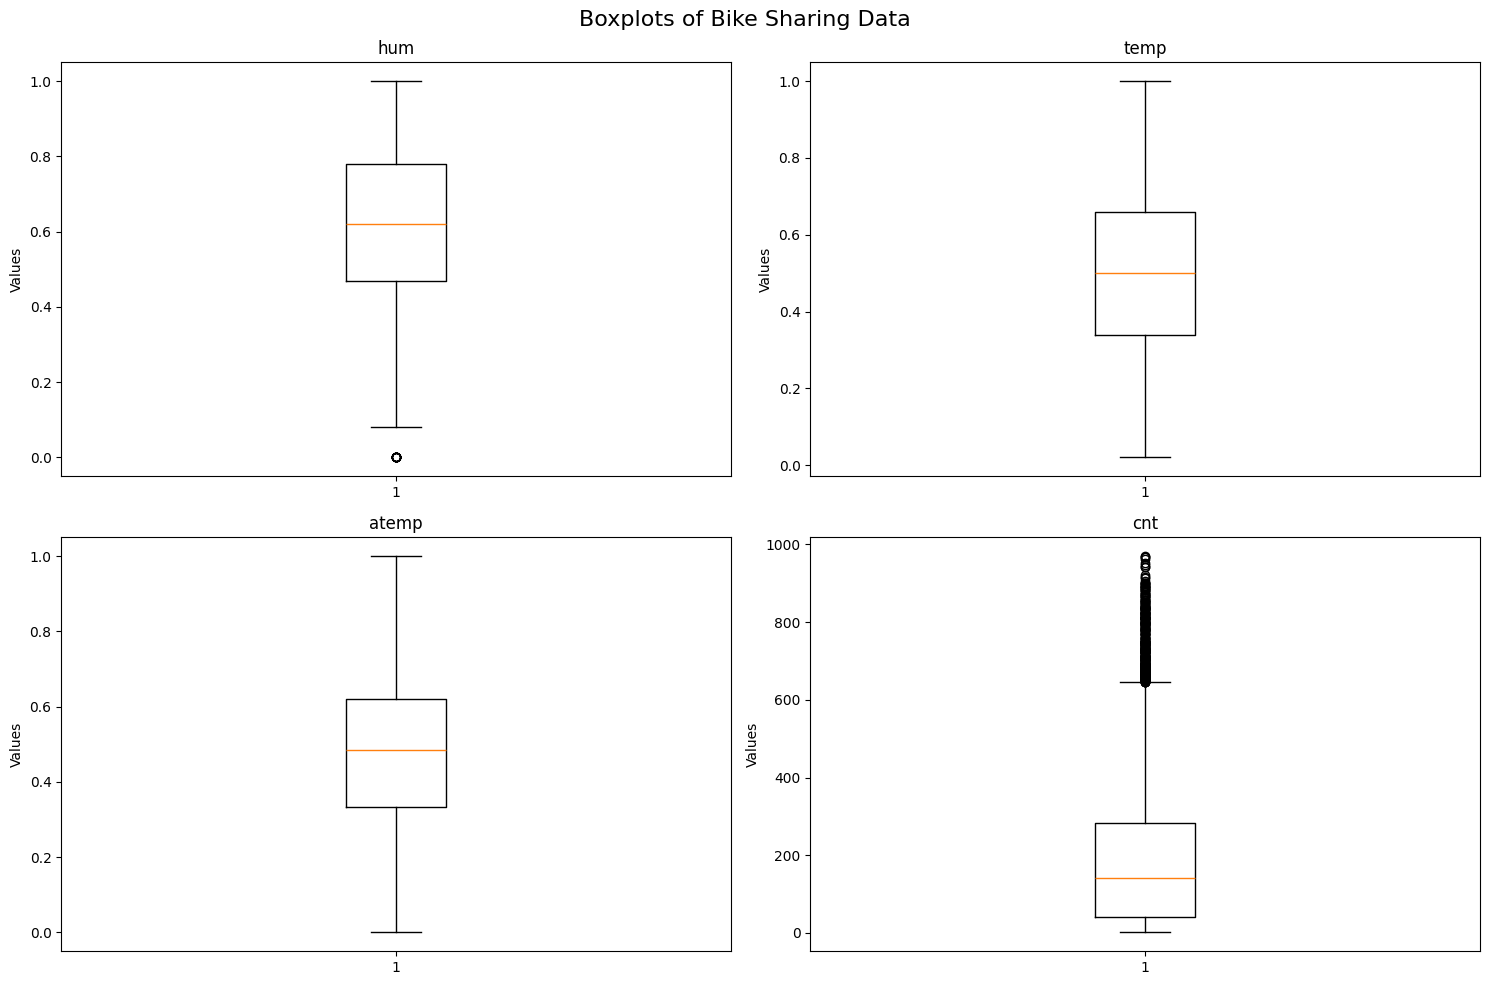

In [16]:
# Set up the plot
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Boxplots of Bike Sharing Data', fontsize=16)

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Create boxplots using a for loop
for i, column in enumerate(num_columns):
    axes[i].boxplot(bike[column])
    axes[i].set_title(column)
    axes[i].set_ylabel('Values')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

In [17]:
# Outliers for casual check
outliers = bike[bike['cnt'] >= 614]

# Count occurrences of each dteday
dteday_counts = outliers['dteday'].value_counts()

# Filter for dteday values that occur more than once
repeated_dtedays = dteday_counts[dteday_counts > 1].index

# Filter outliers for those dteday values
outliers_with_repeated_dtedays = outliers[outliers['dteday'].isin(repeated_dtedays)]
outliers_with_repeated_dtedays.sort_values(by='registered', ascending=False)

,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt,day,month
989,2012-09-26,0.48,1,0,4,0.6667,0.74,17,77,876,953,2,9
8333,2012-10-24,0.47,1,0,4,0.6212,0.66,17,87,876,963,2,10
9118,2012-10-10,0.43,1,0,4,0.5455,0.58,17,91,857,948,2,10
12027,2012-10-16,0.39,1,0,4,0.5000,0.52,17,104,839,943,1,10
8901,2012-10-03,0.65,1,0,4,0.6515,0.70,17,84,833,917,2,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9621,2012-10-06,0.46,1,0,4,0.6212,0.60,15,279,341,620,5,10
6651,2012-03-17,0.53,1,0,1,0.6212,0.62,14,352,338,690,5,3
6317,2012-04-15,0.39,1,0,2,0.6515,0.72,16,286,330,616,6,4
3283,2012-05-19,0.30,1,0,2,0.6515,0.72,15,356,316,672,5,5


In [18]:
# Outliers for humidity check
outliers = bike[bike_new['hum'] <= 0.0500]
outliers

,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt,day,month
345,2011-03-10,0.0,3,0,1,0.3939,0.38,7,1,36,37,3,3
871,2011-03-10,0.0,3,0,1,0.4394,0.44,15,3,11,14,3,3
1645,2011-03-10,0.0,3,0,1,0.3182,0.34,0,3,0,3,3,3
3239,2011-03-10,0.0,2,0,1,0.4394,0.44,17,2,109,111,3,3
3717,2011-03-10,0.0,2,0,1,0.3333,0.34,22,4,30,34,3,3
4924,2011-03-10,0.0,3,0,1,0.3333,0.36,6,0,12,12,3,3
7285,2011-03-10,0.0,3,0,1,0.3182,0.34,1,0,2,2,3,3
7760,2011-03-10,0.0,3,0,1,0.4242,0.42,12,4,30,34,3,3
8412,2011-03-10,0.0,3,0,1,0.3939,0.38,8,1,43,44,3,3
8960,2011-03-10,0.0,3,0,1,0.3485,0.34,23,1,26,27,3,3


In [19]:
results = {}

for col in num_columns:
    q3 = bike_new[col].describe().loc['75%']
    q1 = bike_new[col].describe().loc['25%']

    iqr = q3 - q1

    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    # Count outliers
    upper_outliers = (bike_new[col] > upper).sum()
    lower_outliers = (bike_new[col] < lower).sum()
    total_outliers = upper_outliers + lower_outliers

    # Calculate percentages
    total_count = len(bike_new[col])
    upper_percent = (upper_outliers / total_count) * 100
    lower_percent = (lower_outliers / total_count) * 100
    total_percent = (total_outliers / total_count) * 100

    results[col] = {
        'Upper fence': upper,
        'Lower fence': lower,
        'Upper outliers': upper_outliers,
        'Upper outliers %': upper_percent,
        'Lower outliers': lower_outliers,
        'Lower outliers %': lower_percent,
        'Total outliers': total_outliers,
        'Total outliers %': total_percent
    }

show_outliers = pd.DataFrame(results).T.sort_values(by='Total outliers', ascending=False)
show_outliers

,Upper fence,Lower fence,Upper outliers,Upper outliers %,Lower outliers,Lower outliers %,Total outliers,Total outliers %
cnt,645.00000,-323.00000,338.0,2.778463,0.0,0.000000,338.0,2.778463
hum,1.24500,0.00500,0.0,0.000000,14.0,0.115084,14.0,0.115084
temp,1.14000,-0.14000,0.0,0.000000,0.0,0.000000,0.0,0.000000
atemp,1.05305,-0.09855,0.0,0.000000,0.0,0.000000,0.0,0.000000


In [20]:
bike_new = bike_new[bike_new['hum'] >= 0.00500]
print(bike_new.shape)

(12151, 12)


In [21]:
bike_new = bike_new[bike_new['cnt'] <= 645.00000]
print(bike_new.shape)

(11813, 12)


## **Preprocessing**

In [22]:
cat_columns = bike_new[['weathersit','season','holiday','day','month']]

In [23]:
pd.set_option('display.max_colwidth', None)

pd.DataFrame({
    'feature':cat_columns.columns.values,
    'negative':[True if cat_columns[i].dtype == int and (cat_columns[i] < 0).any() else False for i in cat_columns.columns],
    'n_unique':cat_columns.nunique().values,
    'sample_unique':[cat_columns[i].unique() for i in cat_columns.columns]
})

,feature,negative,n_unique,sample_unique
0,weathersit,False,4,"['Clear', 'Mist', 'Light Rain/Snow', 'Heavy Rain/Snow'] Categories (4, object): ['Clear', 'Heavy Rain/Snow', 'Light Rain/Snow', 'Mist']"
1,season,False,4,"['Fall', 'Spring', 'Summer', 'Winter'] Categories (4, object): ['Fall', 'Spring', 'Summer', 'Winter']"
2,holiday,False,2,"['No', 'Yes'] Categories (2, object): ['No', 'Yes']"
3,day,False,7,"[4, 6, 2, 5, 0, 1, 3] Categories (7, int32): [0, 1, 2, 3, 4, 5, 6]"
4,month,False,12,"[12, 6, 3, 10, 8, ..., 5, 7, 9, 4, 11] Length: 12 Categories (12, int32): [1, 2, 3, 4, ..., 9, 10, 11, 12]"


<Axes: title={'center': 'After Min-Max Scaling'}, xlabel='temp', ylabel='Density'>

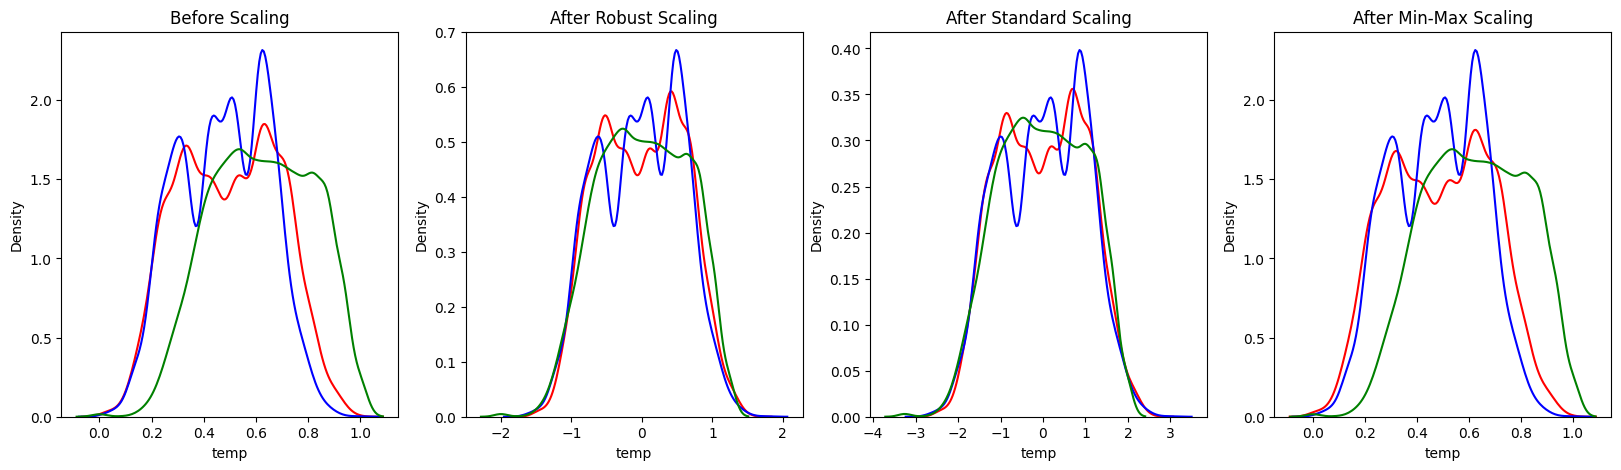

In [24]:
test = num_columns
scalerR = RobustScaler()
robust_df = scalerR.fit_transform(test)
robust_df = pd.DataFrame(robust_df, columns=test.columns)

scalerS = StandardScaler()
standard_df = scalerS.fit_transform(test)
standard_df = pd.DataFrame(standard_df, columns=test.columns)

scalerM = MinMaxScaler()
minmax_df = scalerM.fit_transform(test)
minmax_df = pd.DataFrame(minmax_df, columns=test.columns)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(ncols = 4, figsize =(20, 5))
ax1.set_title('Before Scaling')

sns.kdeplot(test['temp'], ax = ax1, color ='r')
sns.kdeplot(test['atemp'], ax = ax1, color ='b')
sns.kdeplot(test['hum'], ax = ax1, color ='g')
ax2.set_title('After Robust Scaling')

sns.kdeplot(robust_df['temp'], ax = ax2, color ='red')
sns.kdeplot(robust_df['atemp'], ax = ax2, color ='blue')
sns.kdeplot(robust_df['hum'], ax = ax2, color ='green')

ax3.set_title('After Standard Scaling')

sns.kdeplot(standard_df['temp'], ax = ax3, color ='r')
sns.kdeplot(standard_df['atemp'], ax = ax3, color ='b')
sns.kdeplot(standard_df['hum'], ax = ax3, color ='g')

ax4.set_title('After Min-Max Scaling')

sns.kdeplot(minmax_df['temp'], ax = ax4, color ='r')
sns.kdeplot(minmax_df['atemp'], ax = ax4, color ='b')
sns.kdeplot(minmax_df['hum'], ax = ax4, color ='g')

 ***
 # **EDA**
 ***

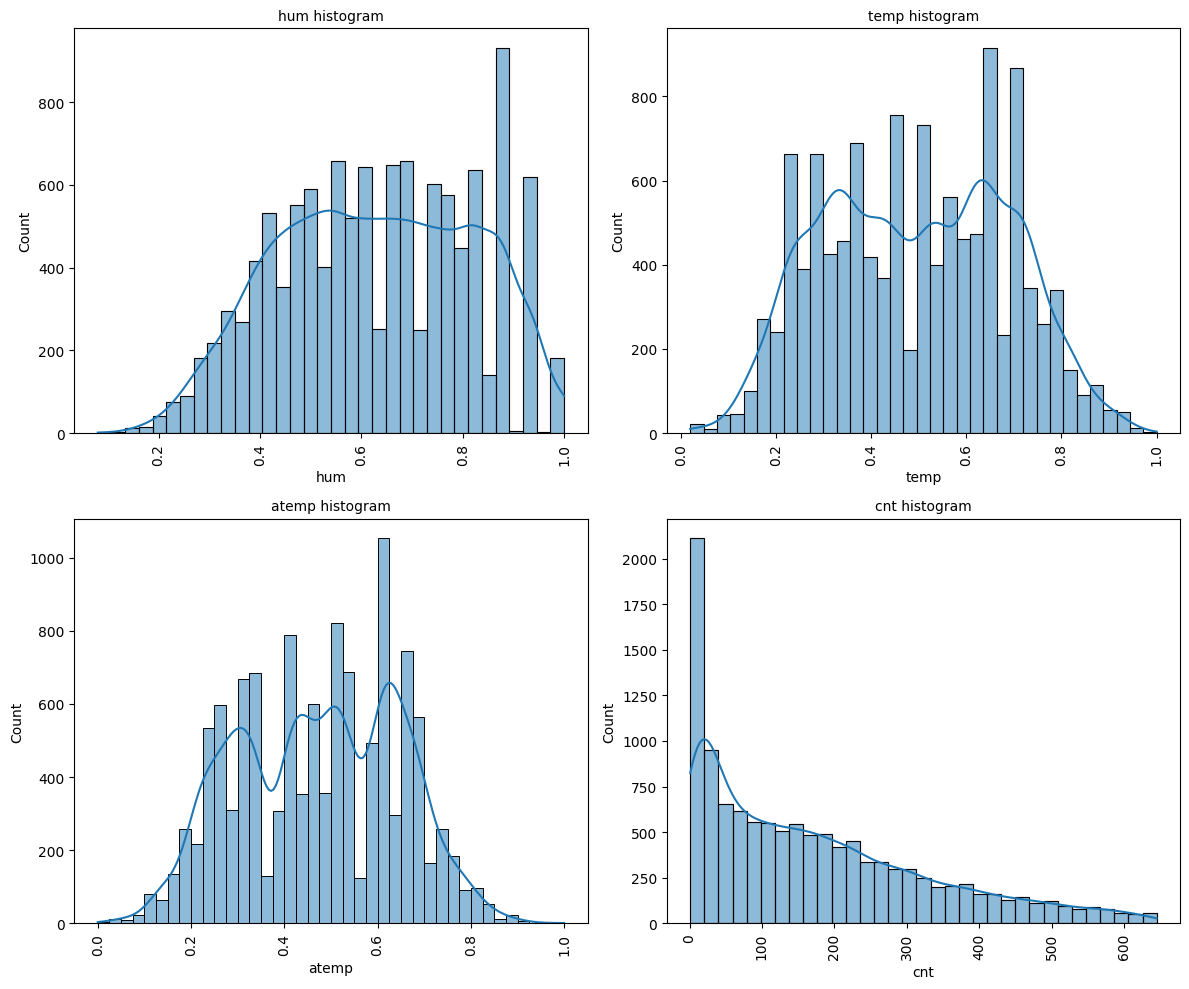

In [25]:
num_feats = bike_new[['hum','temp','atemp','cnt']]
plt.figure(figsize=(12, 10))

for i, var in enumerate(num_feats.columns):
    plt.subplot(2, 2, i + 1)
    plt.title(f"{var} histogram", fontsize=10)
    sns.histplot(data=bike_new, x=var, kde=True)
    plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

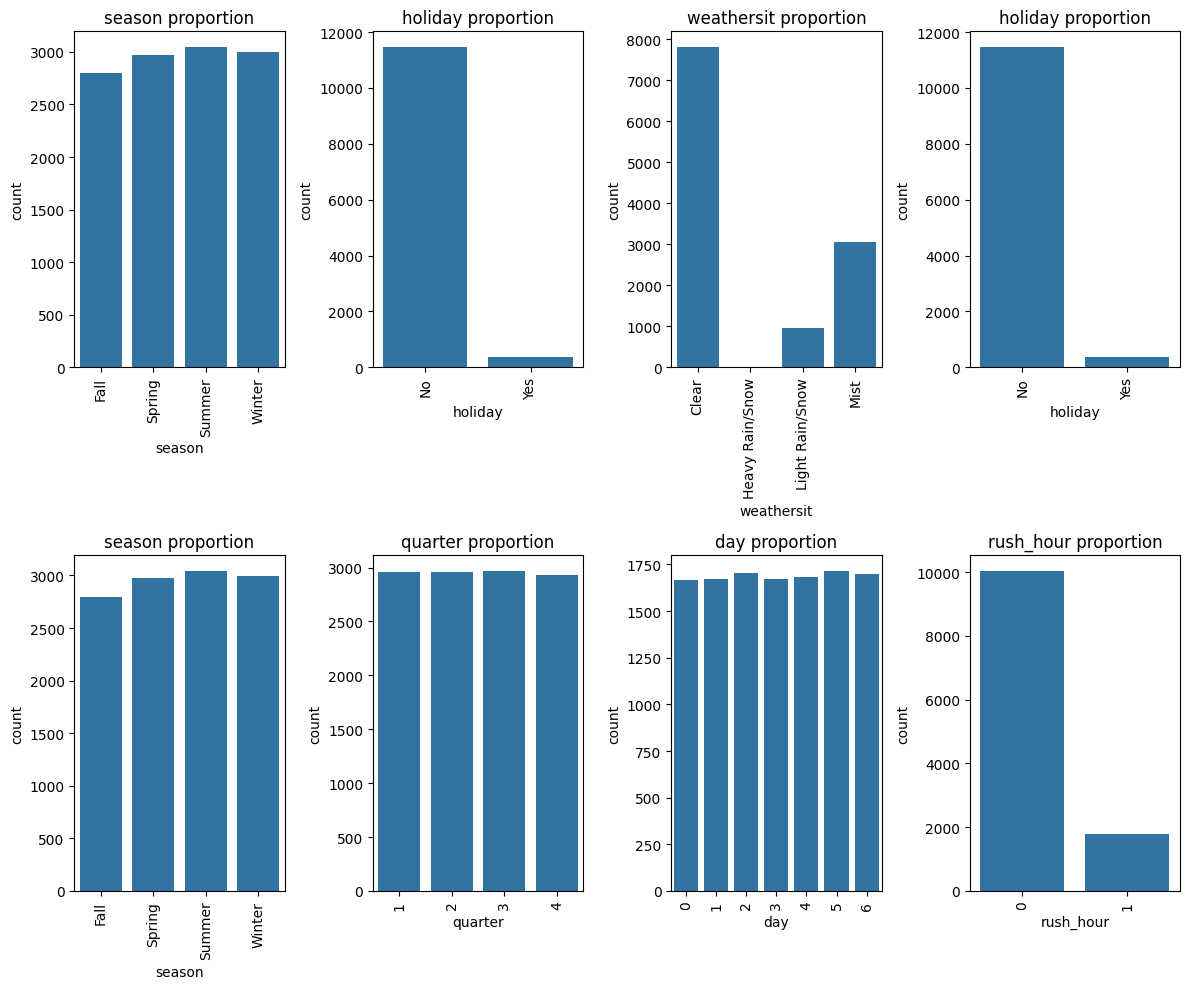

In [26]:
cat_feats = bike_new[['season','holiday','weathersit', 'holiday', 'season','quarter','day','rush_hour']]
plt.figure(figsize=(12, 10))
for i, var in enumerate(cat_feats.columns):
    plt.subplot(2, 4, i+1)
    plt.title(f"{var} proportion")
    sns.countplot(data=bike_new, x=var)
    plt.xticks(rotation=90)
    plt.tight_layout()
plt.show()

 ***
 # **Feature Selection**
 ***

## **Numerical Features Selection**

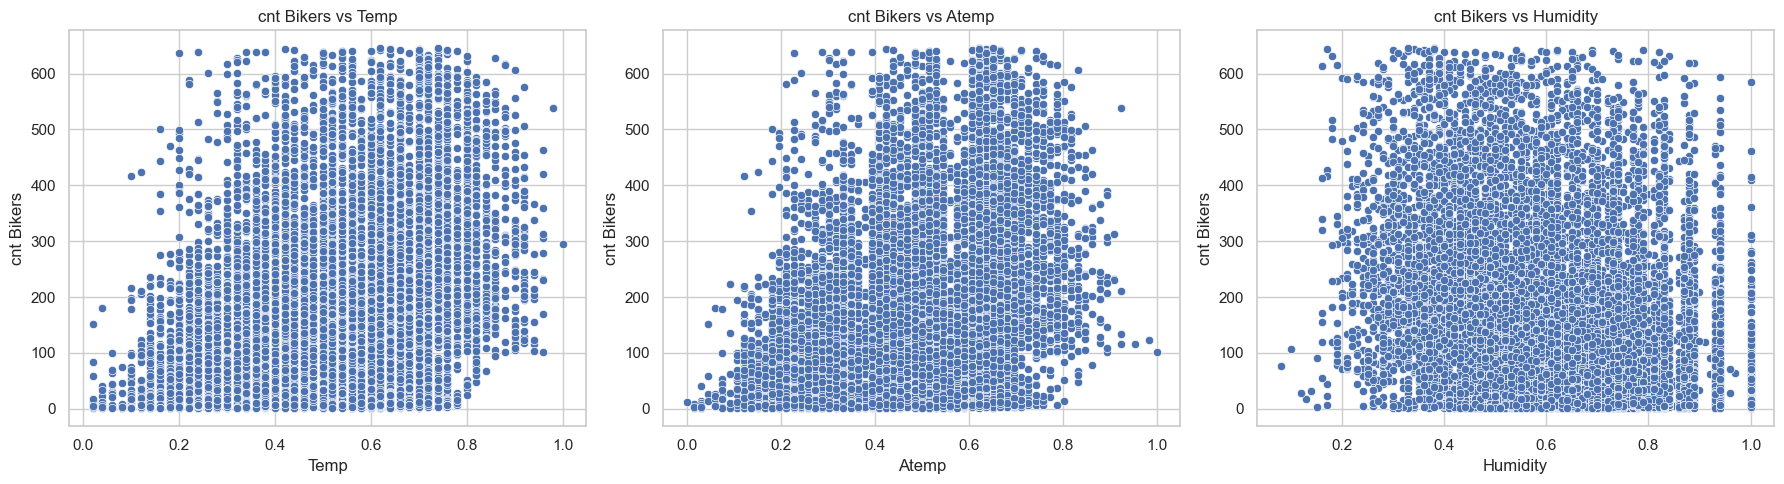

In [27]:
# Set up the plotting environment
sns.set(style="whitegrid")

# Create scatter plots for cnt bikers against temp, atemp, and hum
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot for temp vs cnt
sns.scatterplot(ax=axes[0], x='temp', y='cnt', data=bike_new)
axes[0].set_title('cnt Bikers vs Temp')
axes[0].set_xlabel('Temp')
axes[0].set_ylabel('cnt Bikers')

# Scatter plot for atemp vs cnt
sns.scatterplot(ax=axes[1], x='atemp', y='cnt', data=bike_new)
axes[1].set_title('cnt Bikers vs Atemp')
axes[1].set_xlabel('Atemp')
axes[1].set_ylabel('cnt Bikers')

# Scatter plot for hum vs cnt
sns.scatterplot(ax=axes[2], x='hum', y='cnt', data=bike_new)
axes[2].set_title('cnt Bikers vs Humidity')
axes[2].set_xlabel('Humidity')
axes[2].set_ylabel('cnt Bikers')

# Show the plots
plt.tight_layout()
plt.show()

In [28]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.160
Model:                            OLS   Adj. R-squared:                  0.160
Method:                 Least Squares   F-statistic:                     2253.
Date:                Tue, 16 Jul 2024   Prob (F-statistic):               0.00
Time:                        15:21:50   Log-Likelihood:                -75379.
No. Observations:               11813   AIC:                         1.508e+05
Df Residuals:                   11811   BIC:                         1.508e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.1420      3.623      3.627      0.0

In [29]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['atemp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.157
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     2206.
Date:                Tue, 16 Jul 2024   Prob (F-statistic):               0.00
Time:                        15:21:50   Log-Likelihood:                -75399.
No. Observations:               11813   AIC:                         1.508e+05
Df Residuals:                   11811   BIC:                         1.508e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.0520      3.858      0.791      0.4

In [30]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.108
Model:                            OLS   Adj. R-squared:                  0.108
Method:                 Least Squares   F-statistic:                     1426.
Date:                Tue, 16 Jul 2024   Prob (F-statistic):          8.94e-295
Time:                        15:21:50   Log-Likelihood:                -75737.
No. Observations:               11813   AIC:                         1.515e+05
Df Residuals:                   11811   BIC:                         1.515e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        342.1806      4.670     73.265      0.0

In [31]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp','atemp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.160
Model:                            OLS   Adj. R-squared:                  0.160
Method:                 Least Squares   F-statistic:                     1127.
Date:                Tue, 16 Jul 2024   Prob (F-statistic):               0.00
Time:                        15:21:50   Log-Likelihood:                -75378.
No. Observations:               11813   AIC:                         1.508e+05
Df Residuals:                   11810   BIC:                         1.508e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.0452      4.049      2.728      0.0

In [32]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp','hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.254
Model:                            OLS   Adj. R-squared:                  0.253
Method:                 Least Squares   F-statistic:                     2006.
Date:                Tue, 16 Jul 2024   Prob (F-statistic):               0.00
Time:                        15:21:51   Log-Likelihood:                -74683.
No. Observations:               11813   AIC:                         1.494e+05
Df Residuals:                   11810   BIC:                         1.494e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        177.6390      5.476     32.440      0.0

In [33]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['atemp','hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.255
Model:                            OLS   Adj. R-squared:                  0.255
Method:                 Least Squares   F-statistic:                     2021.
Date:                Tue, 16 Jul 2024   Prob (F-statistic):               0.00
Time:                        15:21:51   Log-Likelihood:                -74672.
No. Observations:               11813   AIC:                         1.493e+05
Df Residuals:                   11810   BIC:                         1.494e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        169.2842      5.570     30.393      0.0

In [34]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp','atemp','hum']]))
result = sm_lm.fit()

In [35]:
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.255
Model:                            OLS   Adj. R-squared:                  0.255
Method:                 Least Squares   F-statistic:                     1350.
Date:                Tue, 16 Jul 2024   Prob (F-statistic):               0.00
Time:                        15:21:51   Log-Likelihood:                -74669.
No. Observations:               11813   AIC:                         1.493e+05
Df Residuals:                   11809   BIC:                         1.494e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        170.9548      5.613     30.457      0.0

In [36]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)

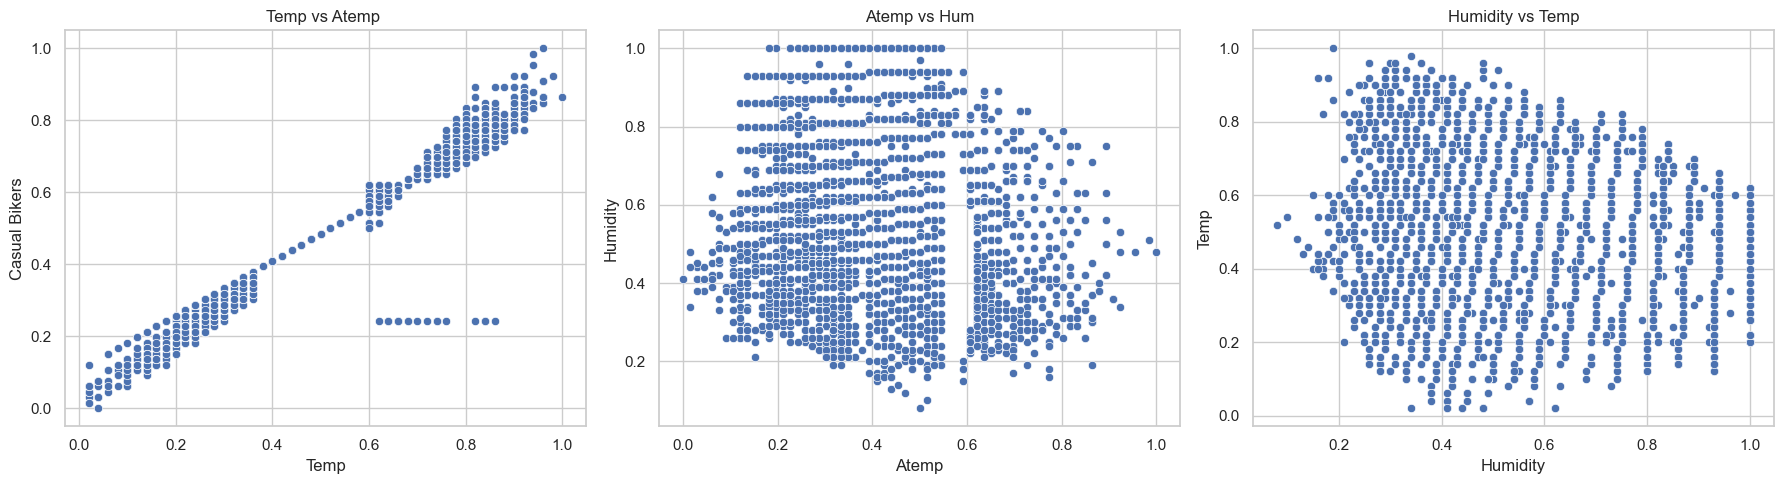

In [37]:
# Set up the plotting environment
sns.set(style="whitegrid")

# Create scatter plots for casual bikers against temp, atemp, and hum
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot for temp vs casual
sns.scatterplot(ax=axes[0], x='temp', y='atemp', data=bike_new)
axes[0].set_title('Temp vs Atemp ')
axes[0].set_xlabel('Temp')
axes[0].set_ylabel('Casual Bikers')

# Scatter plot for atemp vs casual
sns.scatterplot(ax=axes[1], x='atemp', y='hum', data=bike_new)
axes[1].set_title('Atemp vs Hum')
axes[1].set_xlabel('Atemp')
axes[1].set_ylabel('Humidity')

# Scatter plot for hum vs casual
sns.scatterplot(ax=axes[2], x='hum', y='temp', data=bike_new)
axes[2].set_title('Humidity vs Temp')
axes[2].set_xlabel('Humidity')
axes[2].set_ylabel('Temp')

# Show the plots
plt.tight_layout()
plt.show()

In [38]:
calc_vif(bike_new[['temp','atemp']])

,variables,VIF
0,temp,271.514749
1,atemp,271.514749


In [39]:
calc_vif(bike_new[['temp','hum']])

,variables,VIF
0,temp,4.636778
1,hum,4.636778


In [40]:
calc_vif(bike_new[['atemp','hum']])

,variables,VIF
0,atemp,5.047622
1,hum,5.047622


In [41]:
calc_vif(bike_new[['temp','atemp','hum']])

,variables,VIF
0,temp,299.112587
1,atemp,325.615551
2,hum,5.560682


<center>

| F | p-value | R-squared | Adj. R-squared | X1 | X2 | X3 | VIF |
|---------|-------------------------|------------------------|--------------|--------------|--------------|--------------|--------------|
| 4320    | 0.00               | 0.277              | 0.276    | X    |     |     | 1.00    |
| 4127    | 0.00               | 0.267               | 0.267    |     | X    |     |1.00   |
| 0.267  | 0.00                | 0.128               | 0.128    |     |     | X     | 1.00    |
| 2162    | 0.00                | 0.277               | 0.277    | X    | X    |     | 270.27   |
| 3691    | 0.00                | 0.395               | 0.395   | X    |     | X    | 4.77    |
| 3644    | 0.00                | 0.392               | 0.392  |     | X    | X    | 5.19    |
| 2465    | 0.00                | 0.396               | 0.395 |  X   |  X   |  X   | below   |
|     |     |     |     | 296.13    | 322.4    | 5.69    |     |
<center>

***
# **Model Training**
***

## **Data Splitting**

In [42]:
X = bike_new.drop(columns=['cnt','atemp','month'])
y = bike_new['cnt']

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [45]:
X_test.to_csv('bike_test.csv')

In [101]:
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer

transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(drop='first',sparse_output=False), ['weathersit', 'holiday', 'season','quarter','day','rush_hour']),
], remainder='passthrough')

## **Benchmark Model**

### **Linear Model**

In [102]:
lr = LinearRegression()

In [103]:
log_lr = TransformedTargetRegressor(lr, func=np.log, inverse_func=np.exp)

In [104]:
model = log_lr

score_r2 = []
mean_r2 = []
std_r2 = []

crossval = KFold(n_splits=5, shuffle=True, random_state=42)

estimator = Pipeline([
('preprocessing', transformer),
('scaler', RobustScaler()),
('model', model)
])

# r2
model_cv_r2 = cross_val_score(
estimator,
X_train,
y_train,
cv=crossval,
scoring='r2',
error_score='raise'
)

score_r2.append(np.abs(model_cv_r2))
mean_r2.append(np.abs(model_cv_r2).mean())
std_r2.append(np.abs(model_cv_r2).std())



### **Non-Linear Model**

In [105]:
rf =  RandomForestRegressor(n_estimators=150, random_state=42)
gbc = GradientBoostingRegressor(n_estimators=150, random_state=42)
ada = AdaBoostRegressor(n_estimators=150, random_state=42)
xgb = XGBRegressor(n_estimators=150, random_state=42)

In [106]:
# permodelan dilakukan dalam skala logaritmik, namun kemudian di-inverse kembali untuk interpretasi
# fungsi logaritmik digunakan untuk melinierkan target, memungkinkan prediksi yang lebih baik
log_gbc = TransformedTargetRegressor(gbc, func=np.log, inverse_func=np.exp)
log_ada = TransformedTargetRegressor(ada, func=np.log, inverse_func=np.exp)
log_rf = TransformedTargetRegressor(rf, func=np.log, inverse_func=np.exp)
log_xgb = TransformedTargetRegressor(xgb, func=np.log, inverse_func=np.exp)

In [107]:
# Import necessary libraries
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
import numpy as np

# Assuming log_ada, log_gbc, log_rf, log_xgb, transformer, X_train, and y_train are already defined

# List of models
models = [log_ada, log_gbc, log_rf, log_xgb]

score_rmse = []
mean_rmse = []
std_rmse = []

score_mae = []
mean_mae = []
std_mae = []

score_mape = []
mean_mape = []
std_mape = []

# Searching for the best algorithm based on each metric
for i in models:
    # 5-fold cross-validation
    crossval = KFold(n_splits=5, shuffle=True, random_state=42)

    estimator = Pipeline([
        ('preprocessing', transformer),
        # ('scaler', robust),
        ('model', i)
    ])

    # RMSE
    model_cv_rmse = cross_val_score(
        estimator,
        X_train,
        y_train,
        cv=crossval,
        scoring='neg_root_mean_squared_error',
        error_score='raise'
    )

    score_rmse.append(np.abs(model_cv_rmse))
    mean_rmse.append(np.abs(model_cv_rmse).mean())
    std_rmse.append(np.abs(model_cv_rmse).std())

    # MAE
    model_cv_mae = cross_val_score(
        estimator,
        X_train,
        y_train,
        cv=crossval,
        scoring='neg_mean_absolute_error',
        error_score='raise'
    )

    score_mae.append(np.abs(model_cv_mae))
    mean_mae.append(np.abs(model_cv_mae).mean())
    std_mae.append(np.abs(model_cv_mae).std())

    # MAPE
    model_cv_mape = cross_val_score(
        estimator,
        X_train,
        y_train,
        cv=crossval,
        scoring='neg_mean_absolute_percentage_error',
        error_score='raise'
    )

    score_mape.append(np.abs(model_cv_mape))
    mean_mape.append(np.abs(model_cv_mape).mean())
    std_mape.append(np.abs(model_cv_mape).std())


KeyboardInterrupt: 

In [ ]:
# Evaluasi hasil dari 5 kandidat algoritma yang digunakan
benchmark_train = pd.DataFrame({
    'Model': ['AdaBoost Regressor','GradientBoost Regressor', 'RandomForest Regressor', 'XGBoost Regressor'],
    'Train RMSE': mean_rmse,
    'Std RMSE': std_rmse,
    'Train MAE': mean_mae,
    'Std MAE': std_mae,
    'Train MAPE': mean_mape,
    'Std MAPE': std_mape
}).sort_values('Train RMSE', ascending=True)
benchmark_train

,Model,Train RMSE,Std RMSE,Train MAE,Std MAE,Train MAPE,Std MAPE
3,XGBoost Regressor,61.395296,1.003027,39.984563,0.681719,0.346660,0.009073
2,RandomForest Regressor,65.133816,2.165195,42.519019,1.351699,0.379401,0.014209
1,GradientBoost Regressor,77.227387,0.954939,49.822850,0.599501,0.438470,0.017289
0,AdaBoost Regressor,120.285491,4.242942,77.332301,1.972521,0.616235,0.035818


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import numpy as np

models = [log_ada, log_gbc, log_rf, log_xgb]
# List to store test scores
test_score_rmse = []
test_score_mae = []
test_score_mape = []

# Evaluate each model on the test set
for i in models:
    estimator = Pipeline([
        ('preprocessing', transformer),
        ('model', i)
    ])

    # Fit the model
    estimator.fit(X_train, y_train)

    # Predict on the test set
    y_pred = estimator.predict(X_test)

    # Calculate RMSE
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    test_score_rmse.append(rmse)

    # Calculate MAE
    mae = mean_absolute_error(y_test, y_pred)
    test_score_mae.append(mae)

    # Calculate MAPE
    mape = mean_absolute_percentage_error(y_test, y_pred)
    test_score_mape.append(mape)


In [ ]:
results = {
    'Model': ['AdaBoost Regressor','GradientBoost Regressor', 'RandomForest Regressor', 'XGBoost Regressor'],
    'Test RMSE': test_score_rmse,
    'Test MAE': test_score_mae,
    'Test MAPE': test_score_mape
}

# Creating DataFrame
results_test = pd.DataFrame(results)
results_test.sort_values('Test RMSE', ascending=True)


,Model,Test RMSE,Test MAE,Test MAPE
3,XGBoost Regressor,59.452925,38.665358,0.343668
2,RandomForest Regressor,63.007472,41.317243,0.372956
1,GradientBoost Regressor,77.130647,49.907965,0.432952
0,AdaBoost Regressor,115.480260,73.203453,0.612813


In [ ]:
# combine and compare
benchmark_model = results_test.set_index('Model').join(benchmark_train.set_index('Model'))
benchmark_model.drop(['Train RMSE','Std RMSE','Train MAE','Std MAE','Std MAPE','Test RMSE','Test MAE'],axis=1,inplace=True)
benchmark_model['diff'] = benchmark_model['Train MAPE'] - benchmark_model['Test MAPE']
benchmark_model['diff'] = benchmark_model['diff'].agg('abs')
benchmark_model.sort_values(by='Test MAPE',ascending=True)

,Test MAPE,Train MAPE,diff
Model,,,
XGBoost Regressor,0.343668,0.346660,0.002991
RandomForest Regressor,0.372956,0.379401,0.006445
GradientBoost Regressor,0.432952,0.438470,0.005518
AdaBoost Regressor,0.612813,0.616235,0.003423


In [ ]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, RandomizedSearchCV
from xgboost import XGBRegressor

# Define the transformer and the base regressor
xgb = XGBRegressor(random_state=42)

# Define the pipeline
pipe_model = Pipeline([
    ('preprocess', transformer),
    ('model', TransformedTargetRegressor(regressor=xgb, func=np.log, inverse_func=np.exp))
])

# Define the cross-validation strategy
crossval = KFold(n_splits=5, shuffle=True, random_state=42)

# Define the hyperparameter space
hyperparam_space_xgb = {
    'model__regressor__n_estimators': [100,150, 200,250, 300],
    'model__regressor__max_depth': [3, 5, 7],
    'model__regressor__learning_rate': [0.01, 0.05, 0.1],
    'model__regressor__subsample': [0.8, 0.9, 1.0],
    'model__regressor__colsample_bytree': [0.8, 0.9, 1.0]
}

# Initialize the RandomizedSearchCV
random_search_xgb = RandomizedSearchCV(
    estimator=pipe_model,
    param_distributions=hyperparam_space_xgb,
    cv=crossval,
    scoring='neg_mean_absolute_percentage_error',
    n_iter=100,
    n_jobs=-1,
    random_state=42
)

# Fit the model
random_search_xgb.fit(X_train, y_train)

# Best parameters and best score
print("Best parameters found: ", random_search_xgb.best_params_)
print("Best MAPE: ", -random_search_xgb.best_score_)


Best parameters found:  {'model__regressor__subsample': 0.9, 'model__regressor__n_estimators': 250, 'model__regressor__max_depth': 7, 'model__regressor__learning_rate': 0.1, 'model__regressor__colsample_bytree': 0.9}
Best MAPE:  0.33761846116875516


best parameeters found:  {'model__regressor__subsample': 0.9, 'model__regressor__n_estimators': 250, 'model__regressor__max_depth': 7, 'model__regressor__learning_rate': 0.1, 'model__regressor__colsample_bytree': 0.9}
Best MAPE:  0.33761846116875516

In [ ]:
# # Define model terhadap estimator terbaik
# xgb_tuning = random_search_xgb.best_estimator_

# # xgb_pipeline = Pipeline([
# #     ('preprocess', transformer),
# #     ('modeling', xgb_tuning)
# # ])

# # Fitting model
# xgb_tuning.fit(X_train, y_train)

# # Predict test set
# y_pred_xgb_tuning = xgb_tuning.predict(X_test)

# # Simpan nilai metrics RMSE, MAE & MAPE setelah tuning
# rmse_xgb_tuning = np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuning))
# mae_xgb_tuning = mean_absolute_error(y_test, y_pred_xgb_tuning)
# mape_xgb_tuning = mean_absolute_percentage_error(y_test, y_pred_xgb_tuning)

# score_after_tuning = pd.DataFrame({'MAPE': mape_xgb_tuning,'RMSE':rmse_xgb_tuning,'MAE':mae_xgb_tuning}, index=model.keys())
# score_after_tuning

In [ ]:
# Define model terhadap estimator terbaik
final_model_xgb = XGBRegressor(subsample= 0.9, n_estimators= 250, max_depth= 7, learning_rate= 0.1, colsample_bytree= 0.9)

xgb_pipeline = Pipeline([
    ('preprocess', transformer),
    ('modeling', TransformedTargetRegressor(regressor=final_model_xgb, func=np.log, inverse_func=np.exp))
])

xgb_pipeline.fit(X_train, y_train)
# Predict test set
y_pred_xgb_tuning = xgb_pipeline.predict(X_test)

# Simpan nilai metrics RMSE, MAE & MAPE setelah tuning
rmse_xgb_tuning = np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuning))
mae_xgb_tuning = mean_absolute_error(y_test, y_pred_xgb_tuning)
mape_xgb_tuning = mean_absolute_percentage_error(y_test, y_pred_xgb_tuning)

score_after_tuning = pd.DataFrame({'MAPE': mape_xgb_tuning,'RMSE':rmse_xgb_tuning,'MAE':mae_xgb_tuning}, index=model.keys())
score_after_tuning

AttributeError: 'TransformedTargetRegressor' object has no attribute 'keys'

In [ ]:
# # combine and compare
# benchmark_model = results_test.set_index('Model').join(benchmark_train.set_index('Model'))
# benchmark_model.drop(['Train RMSE','Std RMSE','Train MAE','Std MAE','Std MAPE','Test RMSE','Test MAE'],axis=1,inplace=True)
# benchmark_model['diff'] = benchmark_model['Train MAPE'] - benchmark_model['Test MAPE']
# benchmark_model['diff'] = benchmark_model['diff'].agg('abs')
# benchmark_model.sort_values(by='Test MAPE',ascending=True)

In [ ]:
features = list(transformer.get_feature_names_out())

list_features = []

for feature in features:
    list_features.append('_'.join(feature.split('_')[2:]))

list_features

['weathersit_Heavy Rain/Snow',
 'weathersit_Light Rain/Snow',
 'weathersit_Mist',
 'holiday_Yes',
 'season_Spring',
 'season_Summer',
 'season_Winter',
 'quarter_2',
 'quarter_3',
 'quarter_4',
 'day_1',
 'day_2',
 'day_3',
 'day_4',
 'day_5',
 'day_6',
 'rush_hour_1',
 'hum',
 'temp',
 'hr']

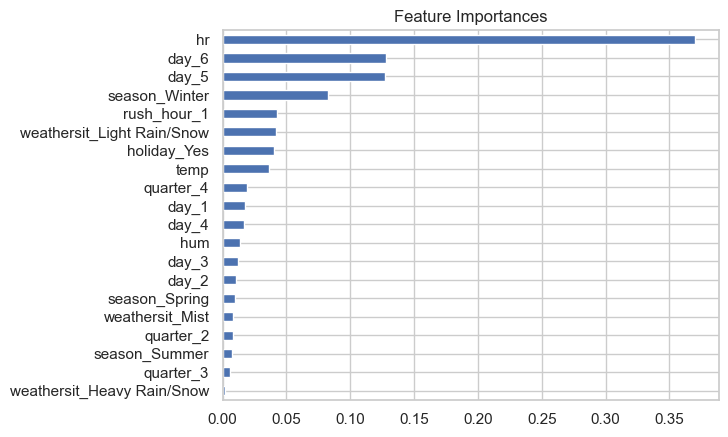

In [ ]:
# Plot feature importances
feature_imp = pd.Series(xgb_pipeline['modeling'].regressor_.feature_importances_, list_features).sort_values(ascending = True)
feature_imp.plot(kind='barh', title='Feature Importances');

In [ ]:
df_result = pd.DataFrame({
    'Actual Demand' : y_test,
    'Model Prediction' : [round(a) for a in y_pred_xgb_tuning]
})

df_result.reset_index()

,index,Actual Demand,Model Prediction
0,12030,445,402
1,3409,75,111
2,8710,17,9
3,3236,51,28
4,6445,213,186
...,...,...,...
2358,5741,62,84
2359,12071,360,329
2360,10800,2,3
2361,4907,197,178


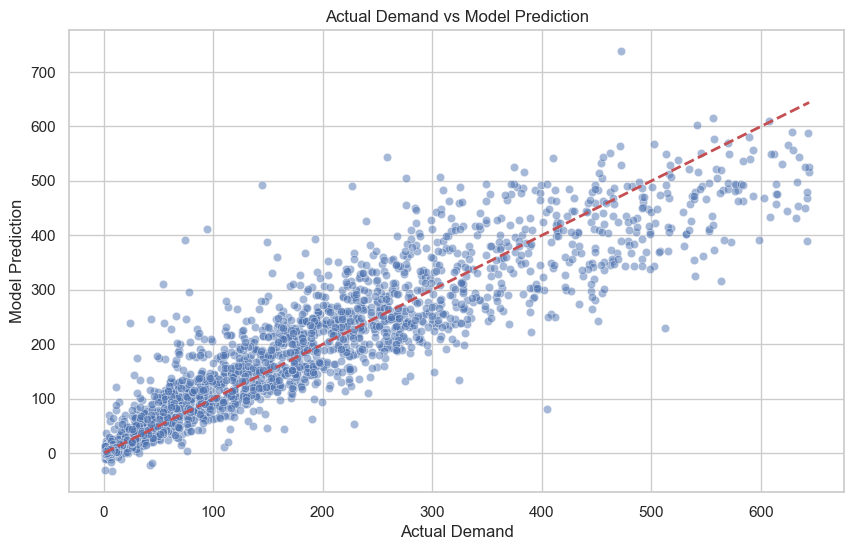

In [ ]:
# Plotting
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Actual Demand', y='Model Prediction', data=df_result, alpha=0.5)
plt.plot([df_result['Actual Demand'].min(), df_result['Actual Demand'].max()],
         [df_result['Actual Demand'].min(), df_result['Actual Demand'].max()],
         'r--', lw=2)
plt.xlabel('Actual Demand')
plt.ylabel('Model Prediction')
plt.title('Actual Demand vs Model Prediction')
plt.show()

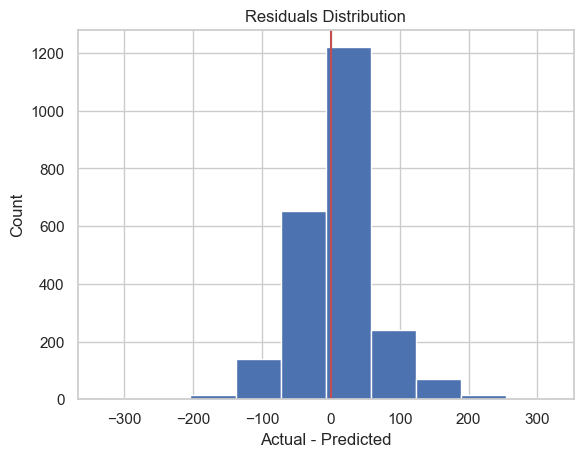

In [ ]:
import matplotlib.pyplot as plt
residuals = (df_result['Actual Demand'] - df_result['Model Prediction'])
plt.hist(residuals)
plt.grid(True)
plt.xlabel('Actual - Predicted')
plt.ylabel('Count')
plt.title('Residuals Distribution')
plt.axvline(color='r')
plt.show()


In [ ]:
value_counts = (residuals > 0).value_counts(sort=False)
print(' Under Estimation: {0:.2f}'.format(value_counts[True]/len(residuals)))
print(' Over  Estimation: {0:.2f}'.format(value_counts[False]/len(residuals)))


 Under Estimation: 0.50
 Over  Estimation: 0.50


In [ ]:
import pickle
final_model = xgb_pipeline
final_model.fit(X_train,y_train)
pickle.dump(final_model, open('Model/xgb_model_final.pkl','wb'))

In [ ]:
import shap

In [ ]:
final_model

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['weathersit', 'holiday',
                                                   'season', 'quarter', 'day',
                                                   'rush_hour'])])),
                ('modeling',
                 TransformedTargetRegressor(func=<ufunc 'log'>,
                                            inverse_func=<ufunc 'exp'>,
                                            regressor=XGBRegressor(base_score=None,
                                                                   booster=None,
                                                                   callb...
                                                                   grow_policy=None,
                                                                   importance_type=None,
                                                                   interaction_constraints=None,
                                                                   learning_rate=0.1,
                                                                   max_bin=None,
                                                                   max_cat_threshold=None,
                                                                   max_cat_to_onehot=None,
                                                                   max_delta_step=None,
                                                                   max_depth=7,
                                                                   max_leaves=None,
                                                                   min_child_weight=None,
                                                                   missing=nan,
                                                                   monotone_constraints=None,
                                                                   multi_strategy=None,
                                                                   n_estimators=250,
                                                                   n_jobs=None,
                                                                   num_parallel_tree=None,
                                                                   random_state=None, ...)))])

In [ ]:
explainer = shap.Explainer(
    final_model[1].predict,
    final_model[0].transform(X_test)
)
shap_values = explainer(final_model[0].transform(X_test))

PermutationExplainer explainer: 2364it [09:05,  4.26it/s]                          


In [ ]:
# shap js
def shap_plot(idx, model, dataset):
    explainerModel = shap.TreeExplainer(model)
    shap_values_model = explainerModel.shap_values(dataset)
    p = shap.force_plot(explainerModel.expected_value, shap_values_model[idx], dataset.iloc[[idx]])
    return (p)

In [ ]:
X_test_preprocessed = pd.DataFrame(final_model[0].transform(X_test))
X_test_preprocessed.columns = list_features
# X_test_preprocessed

In [ ]:
shap.initjs()

In [ ]:
i = 25
X_test.iloc[i], y_test.iloc[i]

(hum             0.73
 weathersit     Clear
 holiday           No
 season        Summer
 temp            0.64
 hr                 7
 day                3
 quarter            3
 rush_hour          1
 Name: 5760, dtype: object,
 532)

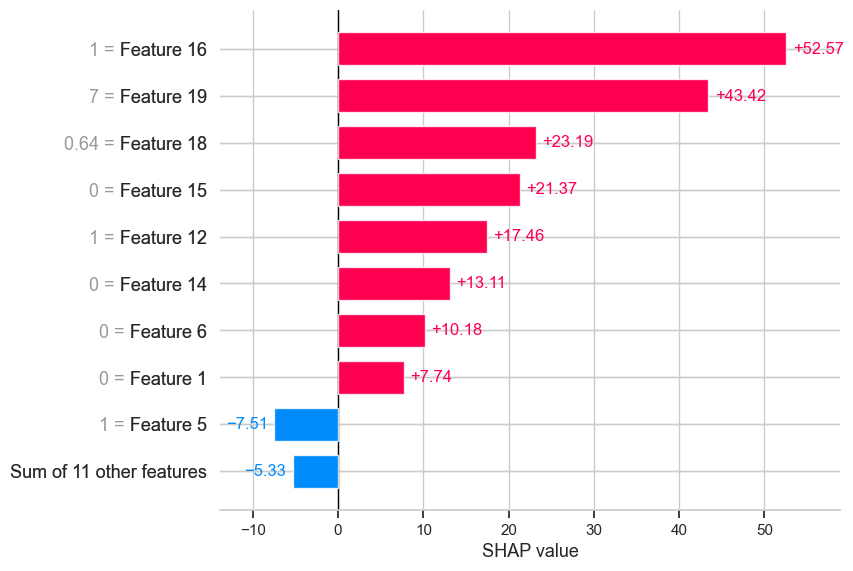

In [ ]:
# shap_values for explain obvervation in test
shap.plots.bar(shap_values[i])

In [ ]:
[i for i in enumerate(list_features)]

[(0, 'weathersit_Heavy Rain/Snow'),
 (1, 'weathersit_Light Rain/Snow'),
 (2, 'weathersit_Mist'),
 (3, 'holiday_Yes'),
 (4, 'season_Spring'),
 (5, 'season_Summer'),
 (6, 'season_Winter'),
 (7, 'quarter_2'),
 (8, 'quarter_3'),
 (9, 'quarter_4'),
 (10, 'day_1'),
 (11, 'day_2'),
 (12, 'day_3'),
 (13, 'day_4'),
 (14, 'day_5'),
 (15, 'day_6'),
 (16, 'rush_hour_1'),
 (17, 'hum'),
 (18, 'temp'),
 (19, 'hr')]

In [ ]:
# let's compare the real result
i = 30

# Access the inner tree-based model within the TransformedTargetRegressor
inner_model = final_model['modeling'].regressor_

shap_plot(
    i,
    inner_model,  # Pass the inner tree-based model
    X_test_preprocessed
)

Interpretation of the Residuals Distribution
Residuals Centered Around Zero:

The highest bar in the histogram is centered around zero, indicating that most of the residuals are close to zero. This suggests that the model's predictions are generally close to the actual values.
Symmetry of the Distribution:

The residuals appear to be symmetrically distributed around zero, suggesting that the model does not have a systematic bias towards underestimation or overestimation. This is a good sign as it indicates the model is balanced in its errors.
Spread of the Residuals:

The majority of residuals fall within a range of -100 to 100. There are fewer residuals beyond this range, which indicates that extreme errors are less common.
The spread of the residuals can give insights into the model's accuracy. A narrower spread would indicate more precise predictions, while a wider spread would suggest more variability in the model's predictions.
Outliers:

There are some residuals beyond the -100 and 100 range, indicating a few cases where the model significantly underestimates or overestimates the actual values. These outliers can be further investigated to understand the conditions under which the model performs poorly.
Red Line at Zero:

The red vertical line at zero emphasizes the central point of the residuals distribution. The fact that the majority of the residuals are close to this line further confirms that the model predictions are generally accurate.
Implications
Model Performance:

The concentration of residuals around zero and the symmetry of the distribution indicate that the model has good predictive performance and is not biased towards under or overestimation.
Model Improvement:

The presence of some outliers suggests that there may be specific conditions or data points where the model's performance could be improved. Identifying and addressing these outliers could help enhance the model.
Further Analysis:

Conducting additional diagnostics, such as plotting residuals against predicted values or input features, can help identify patterns or trends that might suggest areas for model refinement.
Next Steps
Investigate Outliers: Look into the cases with large residuals to understand why the model predictions are significantly off for these instances.
Refine Model: Consider improving the model by incorporating more features, tuning hyperparameters, or using a different modeling technique.
Residuals Diagnostics: Perform further residuals diagnostics to ensure that the assumptions of the regression model (e.g., homoscedasticity, normality) are met.